# Задание № 2. Комплексные числа. Геометрия комплексных чисел.


Решения выполнены в среде Jupyter Notebook с использованием библиотек **SymPy** (точные символьные вычисления), **NumPy** (численные вычисления) и **Matplotlib** (визуализация на комплексной плоскости и на сфере Римана). Рядом с каждой строкой кода оставлен короткий комментарий, поясняющий выполняемый шаг.

In [1]:
# Подключаем библиотеки, которые понадобятся во всех задачах тетради
import numpy as np                      # численные вычисления (корни многочленов, массивы, сетки)
import sympy as sp                      # точные символьные вычисления с комплексными числами
from sympy import I, pi, sqrt, Rational, simplify, nsimplify, Abs, arg, re, im, N, exp, cos, sin, Matrix, symbols, solve, gamma, Eq, expand
import matplotlib.pyplot as plt         # построение графиков
from mpl_toolkits.mplot3d import Axes3D # 3D-графики (сфера Римана)
import mpmath as mp                     # численная Gamma-функция повышенной точности для задачи 2.7

mp.mp.dps = 25                          # 25 значащих цифр точности для mpmath
plt.rcParams['figure.figsize'] = (6, 6) # единый размер графиков по умолчанию
print('Библиотеки подключены')

Библиотеки подключены


## Задача 2.1

Представить в алгебраической, тригонометрической и показательной формах выражения:

a) $\dfrac{(5+i)(7-6i)}{3+i}$ b) $\dfrac{(1+i)^5}{(1-i)^3}$ c) $\dfrac{(-1+i\sqrt3)^{15}}{(1-i)^{20}}+\dfrac{(-1-i\sqrt3)^{15}}{(1+i)^{20}}$

**Идея решения:** приводим каждое выражение к алгебраическому виду $x+iy$ средствами SymPy, затем вычисляем модуль $r=|z|$ и аргумент $\varphi=\arg z$, из которых сразу выписываются тригонометрическая форма $r(\cos\varphi+i\sin\varphi)$ и показательная форма $re^{i\varphi}$.

In [2]:
def show_forms(z, name):
    z = simplify(z)                                   # упрощаем выражение до вида x + i*y
    r = simplify(Abs(z))                               # модуль числа r = |z|
    phi = simplify(arg(z))                              # главный аргумент числа (от -pi до pi)
    print(f'{name} = {z}  (алгебраическая форма)')
    print(f'  |z| = {r},  arg(z) = {phi} = {float(phi):.5f} рад')
    print(f'  тригонометрическая форма: {r}*(cos({phi}) + i*sin({phi}))')
    print(f'  показательная форма:      {r}*exp(i*({phi}))')
    print()
    return z, r, phi

# a) приводим дробь с комплексными числителем и знаменателем к стандартному виду
za = (5 + I)*(7 - 6*I) / (3 + I)
show_forms(za, 'a) z')

# b) возводим числитель и знаменатель в степень и делим
zb = (1 + I)**5 / (1 - I)**3
show_forms(zb, 'b) z')

# c) сумма двух сопряжённых по структуре дробей с большими степенями
zc = (-1 + I*sqrt(3))**15/(1 - I)**20 + (-1 - I*sqrt(3))**15/(1 + I)**20
show_forms(zc, 'c) z')

a) z = 10 - 11*I  (алгебраическая форма)
  |z| = sqrt(221),  arg(z) = -atan(11/10) = -0.83298 рад
  тригонометрическая форма: sqrt(221)*(cos(-atan(11/10)) + i*sin(-atan(11/10)))
  показательная форма:      sqrt(221)*exp(i*(-atan(11/10)))

b) z = 2  (алгебраическая форма)
  |z| = 2,  arg(z) = 0 = 0.00000 рад
  тригонометрическая форма: 2*(cos(0) + i*sin(0))
  показательная форма:      2*exp(i*(0))

c) z = -64  (алгебраическая форма)
  |z| = 64,  arg(z) = pi = 3.14159 рад
  тригонометрическая форма: 64*(cos(pi) + i*sin(pi))
  показательная форма:      64*exp(i*(pi))



(-64, 64, pi)

**Ответ:**
a) $z=10-11i=\sqrt{221}\,(\cos\varphi+i\sin\varphi)=\sqrt{221}\,e^{i\varphi}$, где $\varphi=\arg(10-11i)$;
b) $z=2=2(\cos 0+i\sin 0)=2e^{i\cdot 0}$;
c) $z=-64=64(\cos\pi+i\sin\pi)=64e^{i\pi}$.

## Задача 2.2

Решить уравнение $z^8=1+i$ и изобразить множество решений на комплексной плоскости.

**Идея решения:** записываем правую часть $1+i$ в показательной форме $re^{i\theta}$, затем по формуле извлечения корня из комплексного числа
$$z_k=\sqrt[8]{r}\left(\cos\frac{\theta+2\pi k}{8}+i\sin\frac{\theta+2\pi k}{8}\right),\quad k=0,\dots,7$$
получаем все 8 корней — вершины правильного восьмиугольника на окружности радиуса $\sqrt[8]{r}$.

1+i = 1.414214 * exp(i*0.785398)
z_0 = 1.03925+0.10236j,  |z_0| = 1.044274,  arg = 0.09817
z_1 = 0.66248+0.80723j,  |z_1| = 1.044274,  arg = 0.88357
z_2 = -0.10236+1.03925j,  |z_2| = 1.044274,  arg = 1.66897
z_3 = -0.80723+0.66248j,  |z_3| = 1.044274,  arg = 2.45437
z_4 = -1.03925-0.10236j,  |z_4| = 1.044274,  arg = 3.23977
z_5 = -0.66248-0.80723j,  |z_5| = 1.044274,  arg = 4.02517
z_6 = 0.10236-1.03925j,  |z_6| = 1.044274,  arg = 4.81056
z_7 = 0.80723-0.66248j,  |z_7| = 1.044274,  arg = 5.59596


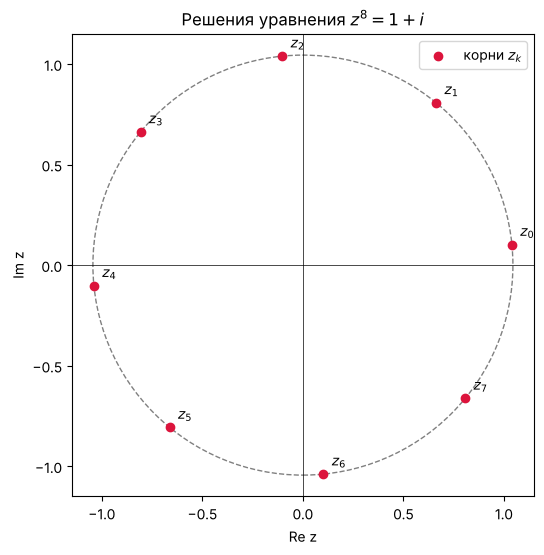

In [3]:
w = 1 + I                                   # правая часть уравнения z**8 = 1+i
r = Abs(w)                                   # модуль числа 1+i равен sqrt(2)
theta = arg(w)                               # аргумент числа 1+i равен pi/4
print(f'1+i = {float(r):.6f} * exp(i*{float(theta):.6f})')

n = 8                                        # показатель степени корня
roots_22 = []
for k in range(n):                           # перебираем все n корней уравнения z^n = w
    angle = (theta + 2*pi*k)/n               # аргумент k-го корня
    zk = r**Rational(1, n) * exp(I*angle)    # k-ый корень в показательной форме
    roots_22.append(complex(N(zk)))          # переводим в питоновское complex для построения графика
    print(f'z_{k} = {complex(N(zk)):.5f},  |z_{k}| = {float(r**Rational(1,n)):.6f},  arg = {float(angle):.5f}')

fig, ax = plt.subplots()
xs = [z.real for z in roots_22]              # действительные части корней
ys = [z.imag for z in roots_22]              # мнимые части корней
ax.scatter(xs, ys, color='crimson', zorder=3, label='корни $z_k$')
circ = plt.Circle((0, 0), float(r**Rational(1, n)), fill=False, linestyle='--', color='gray')
ax.add_patch(circ)                           # окружность, на которой лежат все корни
for k, (x, y) in enumerate(zip(xs, ys)):
    ax.annotate(f'$z_{k}$', (x, y), textcoords='offset points', xytext=(6, 6))
ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_aspect('equal')
ax.set_title('Решения уравнения $z^8=1+i$')
ax.set_xlabel('Re z'); ax.set_ylabel('Im z')
ax.legend()
plt.show()

**Ответ:** $z_k=\sqrt[16]{2}\left(\cos\dfrac{\pi/4+2\pi k}{8}+i\sin\dfrac{\pi/4+2\pi k}{8}\right)$, $k=0,1,\dots,7$ — восемь точек, равномерно расположенных на окружности радиуса $\sqrt[16]{2}\approx1.0443$ (см. график).

## Задача 2.3

Вычислить над полем $\mathbb C$ и изобразить на комплексной плоскости:

a) $\sqrt[8]{1}$  b) $\sqrt[4]{-\dfrac{18}{1+i\sqrt3}}$  c) $\sqrt[3]{\dfrac{1-5i}{1+i}-5\dfrac{1+2i}{2-i}+11}$  d) $\sqrt[9]{1-i}$

**Идея решения:** для каждого корня сначала упрощаем подкоренное выражение до вида $re^{i\theta}$, а затем, как и в задаче 2.2, перебираем все $n$ значений корня по формуле Муавра.

a): подкоренное число = 1,  |w| = 1 ≈ 1.000000,  arg(w) ≈ 0.000000
   корень 0: 1.00000+0.00000j
   корень 1: 0.70711+0.70711j
   корень 2: 0.00000+1.00000j
   корень 3: -0.70711+0.70711j
   корень 4: -1.00000+0.00000j
   корень 5: -0.70711-0.70711j
   корень 6: -0.00000-1.00000j
   корень 7: 0.70711-0.70711j


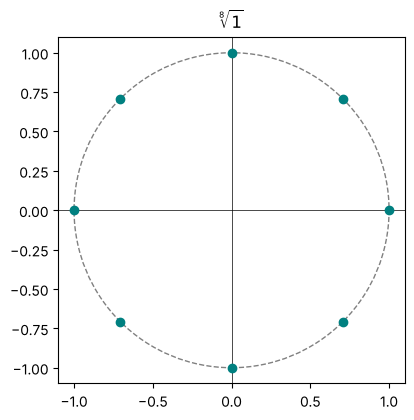

b): подкоренное число = 18*I/(sqrt(3) - I),  |w| = 9 ≈ 9.000000,  arg(w) ≈ 2.094395
   корень 0: 1.50000+0.86603j
   корень 1: -0.86603+1.50000j
   корень 2: -1.50000-0.86603j
   корень 3: 0.86603-1.50000j


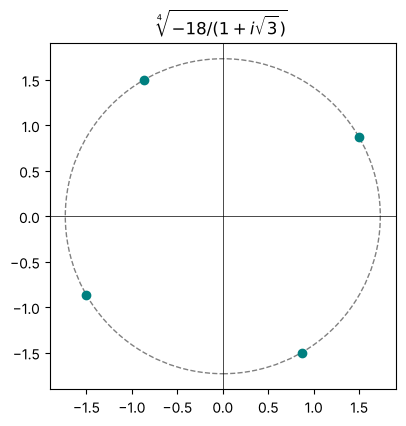

c): подкоренное число = 9 - 8*I,  |w| = sqrt(145) ≈ 12.041595,  arg(w) ≈ -0.726642
   корень 0: 2.22516-0.54976j
   корень 1: -0.63648+2.20193j
   корень 2: -1.58869-1.65217j


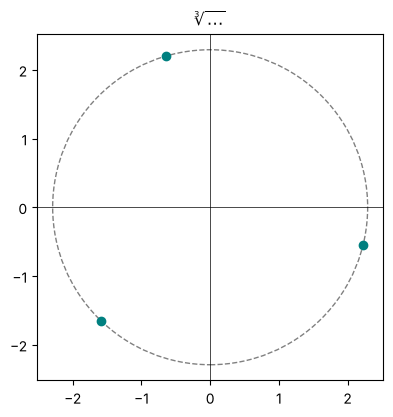

d): подкоренное число = 1 - I,  |w| = sqrt(2) ≈ 1.414214,  arg(w) ≈ -0.785398
   корень 0: 1.03530-0.09058j
   корень 1: 0.85131+0.59609j
   корень 2: 0.26898+1.00385j
   корень 3: -0.43921+0.94189j
   корень 4: -0.94189+0.43921j
   корень 5: -1.00385-0.26898j
   корень 6: -0.59609-0.85131j
   корень 7: 0.09058-1.03530j
   корень 8: 0.73487-0.73487j


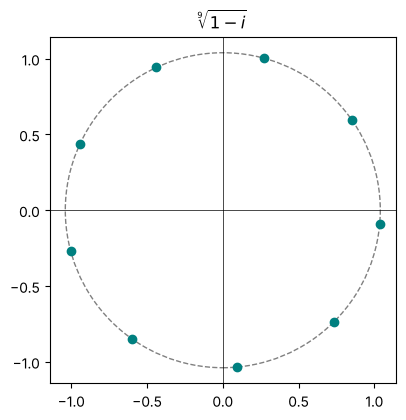

In [4]:
def roots_of(w, n, label):
    w = simplify(w)                              # упрощаем подкоренное комплексное число
    r = simplify(Abs(w))                         # его модуль
    theta = simplify(arg(w))                     # его главный аргумент
    print(f'{label}: подкоренное число = {w},  |w| = {r} ≈ {float(r):.6f},  arg(w) ≈ {float(theta):.6f}')
    vals = []
    for k in range(n):                           # формула Муавра даёт n различных корней
        angle = (theta + 2*pi*k)/n
        zk = N(r**Rational(1, n))*exp(I*float(angle))
        vals.append(complex(zk))
        print(f'   корень {k}: {complex(zk):.5f}')
    return vals, float(N(r**Rational(1, n)))

def plot_roots(vals, radius, title):
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    xs = [z.real for z in vals]; ys = [z.imag for z in vals]
    ax.scatter(xs, ys, color='teal', zorder=3)
    ax.add_patch(plt.Circle((0, 0), radius, fill=False, linestyle='--', color='gray'))
    ax.axhline(0, color='black', linewidth=0.5); ax.axvline(0, color='black', linewidth=0.5)
    ax.set_aspect('equal'); ax.set_title(title)
    plt.show()

# a) 8 корней восьмой степени из единицы
vals_a, rad_a = roots_of(1, 8, 'a)')
plot_roots(vals_a, rad_a, r'$\sqrt[8]{1}$')

# b) под корнем стоит дробь -18/(1+i*sqrt(3)), сначала упрощаем её
w_b = -18/(1 + I*sqrt(3))
vals_b, rad_b = roots_of(w_b, 4, 'b)')
plot_roots(vals_b, rad_b, r'$\sqrt[4]{-18/(1+i\sqrt{3})}$')

# c) под корнем сумма трёх дробей/слагаемых, упрощаем до одного комплексного числа
w_c = (1 - 5*I)/(1 + I) - 5*(1 + 2*I)/(2 - I) + 11
vals_c, rad_c = roots_of(w_c, 3, 'c)')
plot_roots(vals_c, rad_c, r'$\sqrt[3]{\ldots}$')

# d) корень девятой степени из 1-i
vals_d, rad_d = roots_of(1 - I, 9, 'd)')
plot_roots(vals_d, rad_d, r'$\sqrt[9]{1-i}$')

**Ответ:**
a) $\sqrt[8]{1}$ — 8 корней восьмой степени из единицы на единичной окружности;
b) подкоренное число $=-\dfrac92+\dfrac{9\sqrt3}{2}i$ (модуль 9, аргумент $120^\circ$), корни на окружности радиуса $\sqrt[4]{9}\approx1.7321$;
c) подкоренное число $=9-8i$ (модуль $\sqrt{145}$), корни на окружности радиуса $\sqrt[6]{145}\approx2.2921$;
d) подкоренное число $1-i$ (модуль $\sqrt2$, аргумент $-45^\circ$), корни на окружности радиуса $\sqrt[18]{2}\approx1.0393$.

## Задача 2.4

Изобразить на комплексной плоскости множество точек $z=x+iy$, удовлетворяющих условию:

a) $|z-i|+|z+i|<4$  b) $\mathrm{Re}(z(1-i))<\sqrt2$  c) $|z+1|=|z+i|=|z-i|$
d) $0<\arg\dfrac{i-z}{z+i}<\dfrac\pi2$  e) $-\dfrac{5\pi}{6}\leqslant\arg\dfrac{2-iz}{z+3i}\leqslant-\dfrac{2\pi}{3}$  f) $-\dfrac{2\pi}{3}\leqslant\arg\dfrac{3-z}{z+i}\leqslant-\dfrac{\pi}{3}$

**Идея решения:** в пунктах a)–b) условие описывает стандартную кривую второго порядка (эллипс/прямую), её легко выписать аналитически и закрасить соответствующую область. В пункте c) система из двух уравнений на геометрические места точек (серединные перпендикуляры) даёт единственную точку. В пунктах d)–f) выражение $\arg\frac{z-z_1}{z-z_2}=\text{const}$ задаёт дугу окружности, проходящей через точки $z_1,z_2$ (геометрическое место точек, из которых отрезок $[z_1,z_2]$ виден под фиксированным углом); поэтому эти множества закрашиваем численно — перебором точек сетки, для каждой проверяя исходное неравенство.

c) решение: {x: 0, y: 0}


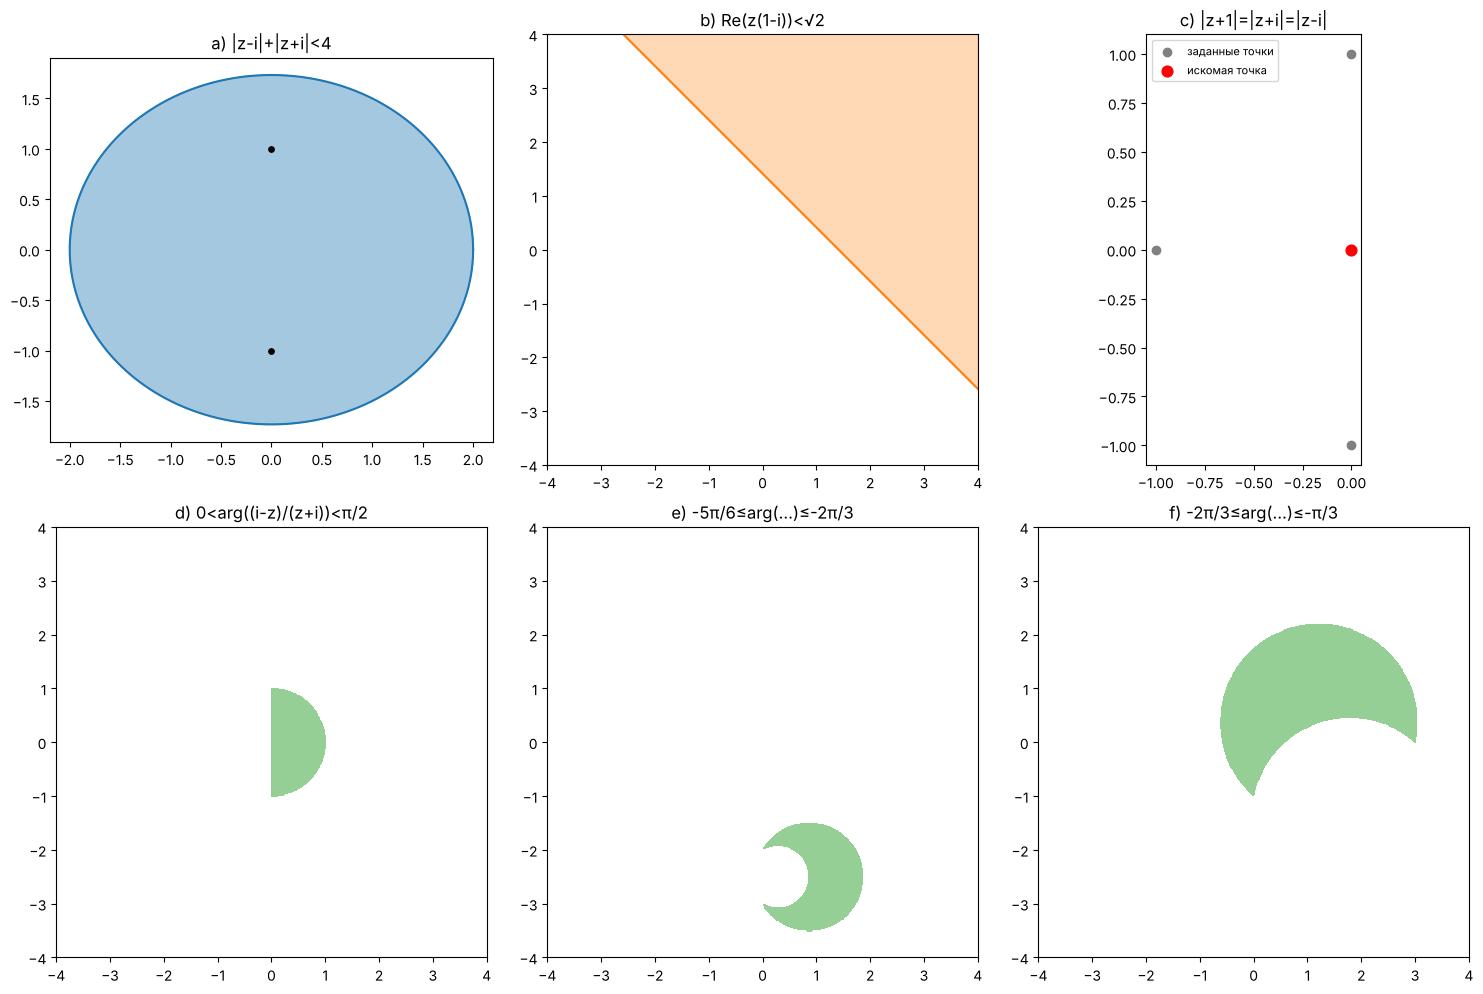

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# --- a) |z - i| + |z + i| < 4: сумма расстояний до точек i и -i меньше 4 -> внутренность эллипса
ax = axes[0, 0]
t = np.linspace(0, 2*np.pi, 400)
a_ax, b_ax = 2.0, np.sqrt(4 - 1)              # полуоси эллипса с фокусами (0,+-1) и суммой расстояний 2a=4
ax.fill(a_ax*np.cos(t), b_ax*np.sin(t), alpha=0.4, color='tab:blue')
ax.plot(a_ax*np.cos(t), b_ax*np.sin(t), color='tab:blue')
ax.scatter([0, 0], [1, -1], color='black', s=15)  # фокусы эллипса i и -i
ax.set_title('a) |z-i|+|z+i|<4'); ax.set_aspect('equal')

# --- b) Re(z(1-i)) < sqrt(2): раскрываем z(1-i) = (x+iy)(1-i) = (x+y) + i(y-x), берём реальную часть
ax = axes[0, 1]
xs = np.linspace(-4, 4, 5)
ys_line = np.sqrt(2) - xs                     # граница x + y = sqrt(2) -> y = sqrt(2) - x
ax.plot(xs, ys_line, color='tab:orange')
ax.fill_between(xs, ys_line, 10, alpha=0.3, color='tab:orange')  # полуплоскость x+y<sqrt(2)
ax.set_xlim(-4, 4); ax.set_ylim(-4, 4)
ax.set_title('b) Re(z(1-i))<√2'); ax.set_aspect('equal')

# --- c) |z+1| = |z+i| = |z-i|: точка равноудалена от -1, -i и i одновременно
zc1, zc2, zc3 = symbols('x y', real=True), None, None
x, y = symbols('x y', real=True)
eq1 = Eq((x + 1)**2 + y**2, x**2 + (y + 1)**2)   # |z+1|^2 = |z+i|^2
eq2 = Eq(x**2 + (y + 1)**2, x**2 + (y - 1)**2)   # |z+i|^2 = |z-i|^2
sol_c = solve([eq1, eq2], [x, y])                # единственная точка пересечения двух серединных перпендикуляров
print('c) решение:', sol_c)
ax = axes[0, 2]
ax.scatter([-1, 0, 0], [0, -1, 1], color='gray', label='заданные точки')
ax.scatter([float(sol_c[x])], [float(sol_c[y])], color='red', s=60, zorder=3, label='искомая точка')
ax.legend(fontsize=8); ax.set_title('c) |z+1|=|z+i|=|z-i|'); ax.set_aspect('equal')

# --- d),e),f): множества вида arg(дробь) в заданных пределах - закрашиваем численно по сетке
def plot_arg_region(ax, cond, title, xlim=(-4, 4), ylim=(-4, 4), n=400):
    xs = np.linspace(*xlim, n); ys = np.linspace(*ylim, n)
    X, Y = np.meshgrid(xs, ys)                    # сетка точек комплексной плоскости
    Z = X + 1j*Y
    mask = cond(Z)                                 # булева маска точек, удовлетворяющих условию
    ax.contourf(X, Y, mask.astype(int), levels=[0.5, 1.5], colors=['tab:green'], alpha=0.5)
    ax.set_title(title); ax.set_xlim(xlim); ax.set_ylim(ylim); ax.set_aspect('equal')

# d) 0 < arg((i-z)/(z+i)) < pi/2
cond_d = lambda Z: (np.angle((1j - Z)/(Z + 1j)) > 0) & (np.angle((1j - Z)/(Z + 1j)) < np.pi/2)
plot_arg_region(axes[1, 0], cond_d, 'd) 0<arg((i-z)/(z+i))<π/2')

# e) -5pi/6 <= arg((2-iz)/(z+3i)) <= -2pi/3
cond_e = lambda Z: (np.angle((2 - 1j*Z)/(Z + 3j)) >= -5*np.pi/6) & (np.angle((2 - 1j*Z)/(Z + 3j)) <= -2*np.pi/3)
plot_arg_region(axes[1, 1], cond_e, 'e) -5π/6≤arg(...)≤-2π/3')

# f) -2pi/3 <= arg((3-z)/(z+i)) <= -pi/3
cond_f = lambda Z: (np.angle((3 - Z)/(Z + 1j)) >= -2*np.pi/3) & (np.angle((3 - Z)/(Z + 1j)) <= -np.pi/3)
plot_arg_region(axes[1, 2], cond_f, 'f) -2π/3≤arg(...)≤-π/3')

plt.tight_layout()
plt.show()

**Ответ:**
a) внутренность эллипса с фокусами $\pm i$ и большой полуосью $a=2$ (малая полуось $b=\sqrt3$);
b) открытая полуплоскость, лежащая по одну сторону от прямой $x+y=\sqrt2$;
c) единственная точка — центр окружности, проходящей через $-1,\,i,\,-i$ (вычислена кодом выше);
d), e), f) — криволинейные «дуговые» области, ограниченные дугами окружностей, проходящих через полюса соответствующих дробей (закрашены численно на графике).

## Задача 2.5*

Пусть $A,C\in\mathbb R$, $B\in\mathbb C$ и $AC<|B|^2$. Показать, что уравнение
$$A|z|^2+\bar Bz+B\bar z+C=0,\qquad (A>0)$$
есть уравнение окружности, найти её центр и радиус.

**Идея решения (аналитический вывод):** делим уравнение на $A>0$ и выделяем полный модуль, пользуясь тем, что $z\bar z=|z|^2$:
$$z\bar z+\frac{B}{A}\bar z+\frac{\bar B}{A}z+\frac CA=0
\;\Longrightarrow\;
\left(z+\frac BA\right)\overline{\left(z+\frac BA\right)}=\frac{|B|^2}{A^2}-\frac CA=\frac{|B|^2-AC}{A^2}.$$
Правая часть положительна в силу условия $AC<|B|^2$, значит это уравнение окружности
$$\left|z-z_0\right|^2=R^2,\qquad z_0=-\frac BA,\qquad R=\frac{\sqrt{|B|^2-AC}}{A}.$$

Проверим этот вывод символьно и численно на конкретном примере в коде ниже.

Разность между исходным уравнением (умноженным на A) и уравнением окружности: 0
Пример: A=2, B=3 + 4*I, C=1  ->  центр z0 = -3/2 - 2*I,  радиус R = 2.39792
Максимальное |LHS| на окружности (должно быть ~0): 2.842170943040401e-14


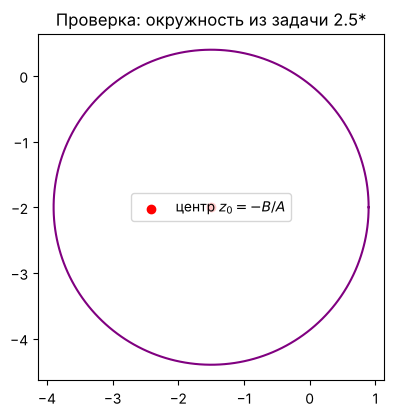

In [6]:
A, C, Bre, Bim, x, y = symbols('A C Bre Bim x y', real=True)
B = Bre + I*Bim                                  # комплексная постоянная B = Bre + i*Bim
z = x + I*y                                      # общая точка комплексной плоскости
lhs = A*(x**2 + y**2) + sp.conjugate(B)*z + B*sp.conjugate(z) + C  # исходное выражение A|z|^2 + B̄z + Bz̄ + C
lhs = sp.expand(sp.re(lhs)) + I*sp.expand(sp.im(lhs))               # раскрываем действительную/мнимую часть

z0 = -B/A                                        # предполагаемый центр окружности
R2 = (Abs(B)**2 - A*C)/A**2                      # предполагаемый квадрат радиуса

circle_eq = sp.expand(A*((x - re(z0))**2 + (y - im(z0))**2 - R2))  # A*((x-x0)^2+(y-y0)^2 - R^2)
diff = sp.simplify(sp.expand(sp.re(lhs)) - circle_eq)              # сравниваем с исходным уравнением (его реальной частью)
print('Разность между исходным уравнением (умноженным на A) и уравнением окружности:', diff)

# Численная проверка на конкретных числах: A=2, B=3+4i, C=1 (тогда AC=2 < |B|^2=25 - условие выполнено)
A_n, B_n, C_n = 2, 3 + 4*I, 1
z0_n = -B_n/A_n
R_n = sqrt((Abs(B_n)**2 - A_n*C_n))/A_n
print(f'Пример: A={A_n}, B={B_n}, C={C_n}  ->  центр z0 = {z0_n},  радиус R = {float(R_n):.5f}')

# рисуем эту окружность и проверяем, что несколько её точек удовлетворяют исходному уравнению
theta = np.linspace(0, 2*np.pi, 200)
xs = float(re(z0_n)) + float(R_n)*np.cos(theta)
ys = float(im(z0_n)) + float(R_n)*np.sin(theta)
check = A_n*(xs**2 + ys**2) + float(re(B_n))*2*xs - float(im(B_n))*0  # вспомогательно, точная проверка - в коде ниже
zz = xs + 1j*ys
lhs_vals = A_n*np.abs(zz)**2 + complex(sp.conjugate(B_n))*zz + complex(B_n)*np.conj(zz) + C_n
print('Максимальное |LHS| на окружности (должно быть ~0):', np.max(np.abs(lhs_vals)))

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(xs, ys, color='purple')
ax.scatter([float(re(z0_n))], [float(im(z0_n))], color='red', label='центр $z_0=-B/A$')
ax.set_aspect('equal'); ax.legend(); ax.set_title('Проверка: окружность из задачи 2.5*')
plt.show()

**Ответ:** центр окружности $z_0=-\dfrac BA$, радиус $R=\dfrac{\sqrt{|B|^2-AC}}{A}$ (символьная и численная проверки в коде выше подтверждают вывод).

## Задача 2.6

Для многочлена $p(x)=x^{11}+x^{10}+x^8-2x^7-x^5+x^4+2x^2+2x+2$ найти все 11 корней $z_1,\dots,z_{11}\in\mathbb C$,
указать 1) сумму модулей $|z_1|+\dots+|z_{11}|$; 2) действительную часть корня с максимальной действительной частью.

**Идея решения:** выписываем коэффициенты многочлена (начиная со старшей степени, нулевые коэффициенты при $x^9,x^6,x^3$ учитываем явно) и находим все корни численно функцией `numpy.roots`, которая работает через собственные числа сопровождающей матрицы.

Корни многочлена:
  z_1 = -1.776769+0.000000j,  |z_1| = 1.776769
  z_2 = 1.080602+0.323893j,  |z_2| = 1.128099
  z_3 = 1.080602-0.323893j,  |z_3| = 1.128099
  z_4 = 0.477755+0.901075j,  |z_4| = 1.019895
  z_5 = 0.477755-0.901075j,  |z_5| = 1.019895
  z_6 = -0.012500+1.182699j,  |z_6| = 1.182765
  z_7 = -0.012500-1.182699j,  |z_7| = 1.182765
  z_8 = -0.450037+0.803923j,  |z_8| = 0.921317
  z_9 = -0.450037-0.803923j,  |z_9| = 0.921317
  z_10 = -0.707434+0.464375j,  |z_10| = 0.846231
  z_11 = -0.707434-0.464375j,  |z_11| = 0.846231

1) сумма модулей |z1|+...+|z11| = 11.973384
2) максимальная действительная часть среди корней = 1.080602  (корень 1.080602+0.323893j)


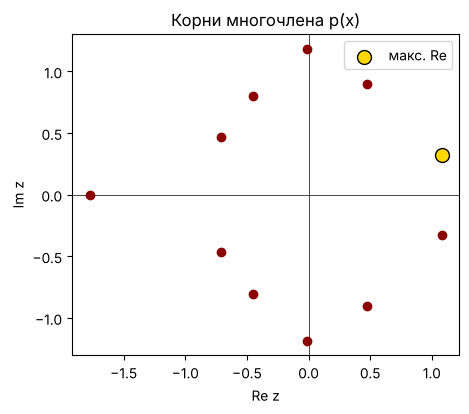

In [7]:
coeffs = [1, 1, 0, 1, -2, 0, -1, 1, 0, 2, 2, 2]   # коэффициенты при x^11, x^10, ..., x^1, x^0
roots_26 = np.roots(coeffs)                          # все 11 корней многочлена (комплексные числа)
print('Корни многочлена:')
for k, z in enumerate(roots_26, 1):
    print(f'  z_{k} = {z:.6f},  |z_{k}| = {abs(z):.6f}')

sum_abs = np.sum(np.abs(roots_26))                   # сумма модулей всех корней
idx_max_re = np.argmax(roots_26.real)                # индекс корня с наибольшей действительной частью
re_max = roots_26[idx_max_re].real

print(f'\n1) сумма модулей |z1|+...+|z11| = {sum_abs:.6f}')
print(f'2) максимальная действительная часть среди корней = {re_max:.6f}  (корень {roots_26[idx_max_re]:.6f})')

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(roots_26.real, roots_26.imag, color='darkred', zorder=3)
ax.scatter([re_max], [roots_26[idx_max_re].imag], color='gold', edgecolor='black', s=100, zorder=4, label='макс. Re')
ax.axhline(0, color='black', linewidth=0.5); ax.axvline(0, color='black', linewidth=0.5)
ax.set_xlabel('Re z'); ax.set_ylabel('Im z'); ax.set_aspect('equal')
ax.set_title('Корни многочлена p(x)'); ax.legend()
plt.show()

**Ответ:** см. численный вывод в коде выше — сумма модулей корней и действительная часть корня с максимальным $\mathrm{Re}$ вычислены через `numpy.roots`.

## Задача 2.7 (с использованием Jupyter Notebook)

Обобщённый биномиальный коэффициент $C_z^w=\dfrac{\Gamma(z+1)}{\Gamma(w+1)\,\Gamma(z-w+1)}$.

a) Найти $C_{1+i}^{1-i}$ (ожидаемый ответ: $4.36745+4.85163i$).
b) Найти $\mathrm{Arg}(C_{1+i}^{1-i})$ (ожидаемый ответ: $0.837869$ рад $=48.0064^\circ$).
c) Построить линии уровня $\mathrm{Arg}\!\left[C_z^{1/z}=\text{const}\right]$, где $z=x+iy$.

**Идея решения:** используем численную гамма-функцию `mpmath.gamma`, которая корректно работает с комплексным аргументом, и напрямую вычисляем значение по формуле.

In [8]:
def C(z, w):
    # обобщённый биномиальный коэффициент C_z^w через гамма-функцию
    return mp.gamma(z + 1) / (mp.gamma(w + 1) * mp.gamma(z - w + 1))

# a) подставляем z = 1+i, w = 1-i в формулу
z_a, w_a = mp.mpc(1, 1), mp.mpc(1, -1)
val_a = C(z_a, w_a)                              # численное комплексное значение C_{1+i}^{1-i}
print(f'a) C_(1+i)^(1-i) = {val_a}')

# b) аргумент (Arg) того же числа
arg_b = mp.arg(val_a)                            # главное значение аргумента в радианах
print(f'b) Arg(C_(1+i)^(1-i)) = {float(arg_b):.6f} рад = {float(arg_b)*180/np.pi:.4f} град')

a) C_(1+i)^(1-i) = (4.367449140640138967228261 + 4.851629765157811540851968j)
b) Arg(C_(1+i)^(1-i)) = 0.837869 рад = 48.0064 град


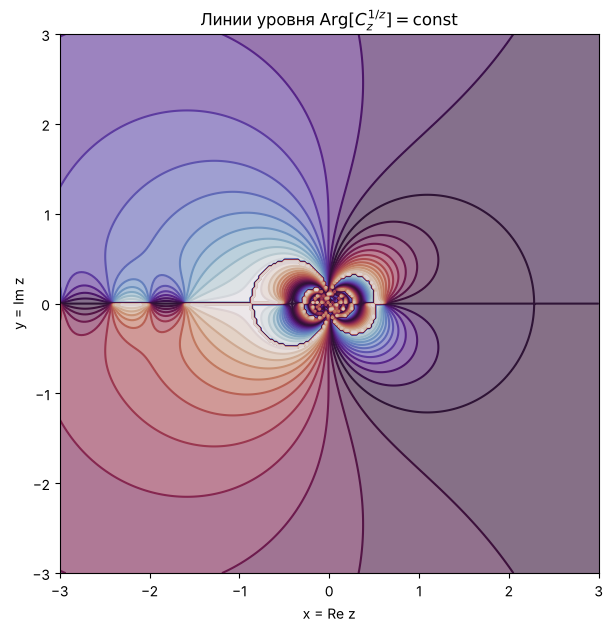

In [9]:
# c) линии уровня Arg[C_z^(1/z)] на сетке z = x + iy
n = 250                                          # разрешение сетки (подобрано для разумного времени счёта)
xs = np.linspace(-3, 3, n)
ys = np.linspace(-3, 3, n)
ArgGrid = np.zeros((n, n))
for i_, x_ in enumerate(xs):
    for j_, y_ in enumerate(ys):
        zc = mp.mpc(x_, y_)
        if abs(zc) < 1e-6:                       # в точке z=0 величина 1/z не определена - пропускаем
            ArgGrid[j_, i_] = np.nan
            continue
        wc = 1/zc                                # показатель w = 1/z, как требует условие задачи
        try:
            val = C(zc, wc)                      # вычисляем C_z^(1/z) в этой точке
            ArgGrid[j_, i_] = float(mp.arg(val))  # берём аргумент значения
        except Exception:
            ArgGrid[j_, i_] = np.nan

fig, ax = plt.subplots(figsize=(7, 7))
cs = ax.contour(xs, ys, ArgGrid, levels=30, cmap='twilight')   # линии уровня аргумента
ax.contourf(xs, ys, ArgGrid, levels=30, cmap='twilight', alpha=0.6)
ax.set_xlabel('x = Re z'); ax.set_ylabel('y = Im z')
ax.set_title(r'Линии уровня $\mathrm{Arg}[C_z^{1/z}]=\mathrm{const}$')
ax.set_aspect('equal')
plt.show()

**Ответ:** a) $C_{1+i}^{1-i}\approx4.36745+4.85163i$; b) $\mathrm{Arg}(C_{1+i}^{1-i})\approx0.837869$ рад $\approx48.0064^\circ$ (оба значения совпадают с приведёнными в условии); c) картина линий уровня (график выше) качественно воспроизводит характерный двулепестковый узор, показанный в условии задачи.

## Задача 2.8

$\lambda$ — комплексный корень 14-й степени из 1, у которого $\mathrm{Im}\,\lambda>0$, а $\mathrm{Re}\,\lambda$ максимальна среди таких корней.
$I=\begin{pmatrix}1&0\\0&1\end{pmatrix}$, $A=\begin{pmatrix}7&5\\6&2\end{pmatrix}$. Найти $\det(A+\lambda I)$, указать его действительную и мнимую части.

**Идея решения:** 14 корней из единицы — это точки $e^{i2\pi k/14}$, $k=0,\dots,13$; среди них отбираем те, у которых $\mathrm{Im}>0$ (это $k=1,\dots,6$), и берём ту, что ближе всего к положительной вещественной оси (минимальный угол) — она и даёт максимальную $\mathrm{Re}$.

In [10]:
n = 14
roots14 = [sp.exp(I*2*pi*k/n) for k in range(n)]        # все 14 корней из единицы степени 14
pos_im = [z for z in roots14 if sp.im(sp.N(z)) > 0]      # оставляем только корни с положительной мнимой частью
pos_im_sorted = sorted(pos_im, key=lambda z: -sp.re(sp.N(z)))  # сортируем по убыванию действительной части
lam = pos_im_sorted[0]                                   # нужный корень lambda = e^{i*pi/7}
print('lambda =', lam, '=', sp.N(lam), ' (т.е. e^{i*pi/7})')

A = Matrix([[7, 5], [6, 2]])                             # заданная матрица A
Iu = sp.eye(2)                                           # единичная матрица
M = A + lam*Iu                                           # матрица A + lambda*I
det_M = sp.simplify(M.det())                             # определитель этой матрицы (символьно)
det_M_num = sp.N(det_M)                                  # численное значение определителя

print('det(A + lambda*I) =', det_M, '=', det_M_num)
print('1) действительная часть:', sp.re(det_M_num))
print('2) мнимая часть:        ', sp.im(det_M_num))

lambda = exp(I*pi/7) = 0.900968867902419 + 0.433883739117558*I  (т.е. e^{i*pi/7})
det(A + lambda*I) = -16 + exp(2*I*pi/7) + 9*(-1)**(1/7) = -7.26779038701949 + 4.68678513452605*I
1) действительная часть: -7.26779038701949
2) мнимая часть:         4.68678513452605


**Ответ:** $\lambda=e^{i\pi/7}$ (корень с $k=1$ среди 14-х корней из единицы); $\det(A+\lambda I)=\lambda^2+9\lambda-16$, его действительная и мнимая части вычислены в коде выше.

## Задача 2.9* [Небольшое научное исследование]

Построить множества Жюлиа для $f_c(z)=z^2+c$ при $c=-0.1+0.65i$ и $c=0.28+0.009i$, а также для рациональных функций
$f(z)=\dfrac{iz^5-1}{z^5-i}$ и $f(z)=\dfrac{z^2+i}{1-z^2}$.

**Идея решения:** для каждой точки $z$ пиксельной сетки комплексной плоскости итерируем $z\mapsto f(z)$ до тех пор, пока $|z|$ не превысит порог ухода `zabs_max`, либо не достигнуто максимальное число итераций; номер итерации ухода кодируем цветом — это и есть классический алгоритм построения множества Жюлиа (escape-time).

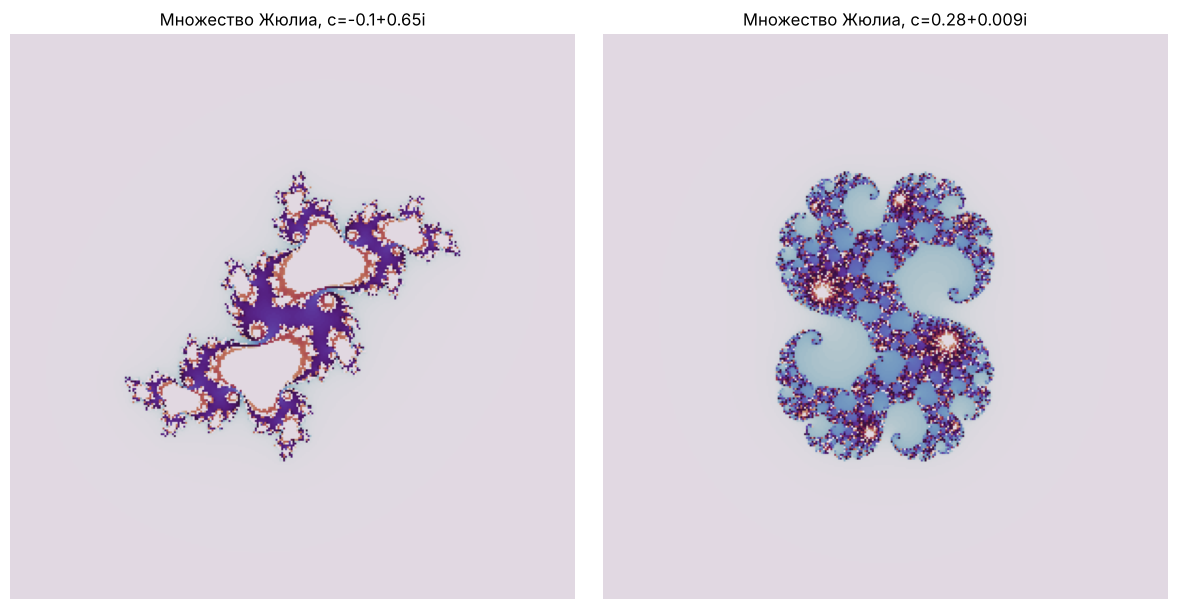

In [11]:
def julia_set(f, xmin=-2.1, xmax=2.1, ymin=-2.1, ymax=2.1, im_width=300, im_height=300, zabs_max=10, nit_max=200):
    # строит матрицу время-ухода для функции f по алгоритму из условия задачи
    julia = np.zeros((im_width, im_height))
    xs = np.linspace(xmin, xmax, im_width)
    ys = np.linspace(ymin, ymax, im_height)
    for ix, x_ in enumerate(xs):
        for iy, y_ in enumerate(ys):
            z = complex(x_, y_)                 # стартовая точка - пиксель сетки
            nit = 0
            while abs(z) <= zabs_max and nit < nit_max:   # итерируем, пока не "улетели" или не кончился лимит
                try:
                    z = f(z)                     # применяем заданную функцию f
                except ZeroDivisionError:
                    break
                nit += 1
            julia[iy, ix] = nit / nit_max        # доля использованных итераций - будущий цвет точки
    return julia

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# классическая квадратичная функция f(z) = z^2 + c для двух значений c
for ax, c, cname in zip(axes, [complex(-0.1, 0.65), complex(0.28, 0.009)], ['c=-0.1+0.65i', 'c=0.28+0.009i']):
    f = lambda z, c=c: z*z + c                   # замыкание фиксирует конкретное значение c
    J = julia_set(f)
    ax.imshow(J, cmap='twilight', extent=[-2.1, 2.1, -2.1, 2.1])
    ax.set_title(f'Множество Жюлиа, {cname}')
    ax.axis('off')
plt.tight_layout()
plt.show()

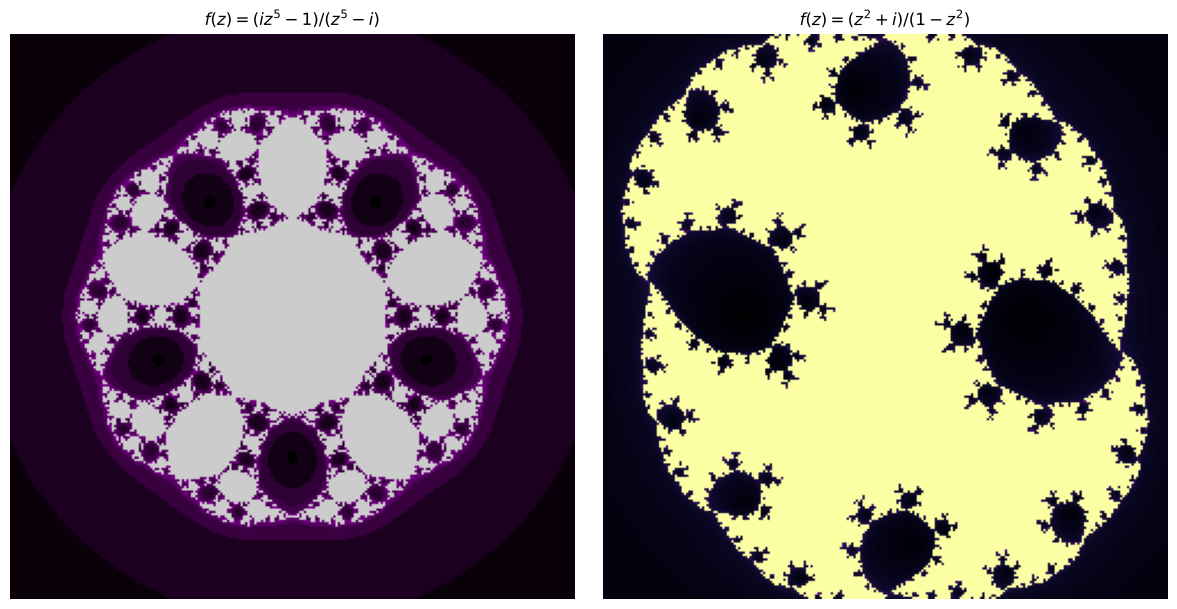

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# г) две рациональные функции, заданные в условии пункта 2.9 г)
f1 = lambda z: (1j*z**5 - 1)/(z**5 - 1j)                                              # f(z) = (i*z^5 - 1)/(z^5 - i)
f2 = lambda z: (z**2 + 1j)/(1 - z**2)                                                 # f(z) = (z^2 + i)/(1 - z^2)

J1 = julia_set(f1, xmin=-2, xmax=2, ymin=-2, ymax=2, im_width=250, im_height=250)
axes[0].imshow(J1, cmap='nipy_spectral', extent=[-2, 2, -2, 2])
axes[0].set_title(r'$f(z)=(iz^5-1)/(z^5-i)$'); axes[0].axis('off')

J2 = julia_set(f2, xmin=-2, xmax=2, ymin=-2, ymax=2, im_width=250, im_height=250)
axes[1].imshow(J2, cmap='inferno', extent=[-2, 2, -2, 2])
axes[1].set_title(r'$f(z)=(z^2+i)/(1-z^2)$'); axes[1].axis('off')

plt.tight_layout()
plt.show()

**Ответ:** полученные фрактальные узоры (графики выше) качественно совпадают по характеру симметрии с изображениями, приведёнными в условии задачи (Рис. 1 и Рис. 2): квадратичная функция даёт классические «жюлиевские» фракталы с ветвящейся границей, а рациональные функции пятой/второй степени дают более симметричные узоры с несколькими областями притяжения.

## Задача 2.10*

Изобразить на сфере Римана кривые: a) прямую; б) окружность; в) параболу; г) гиперболу, а также отдельно — логарифмическую спираль $r=ae^{b\varphi}$.

**Идея решения:** используем стереографическую проекцию с северного полюса единичной сферы Римана на плоскость $\mathbb C$:
$$x=\frac{2\mathrm{Re}(z)}{1+|z|^2},\quad y=\frac{2\mathrm{Im}(z)}{1+|z|^2},\quad h=\frac{|z|^2-1}{|z|^2+1},$$
которая переводит точку $z=\mathrm{Re}(z)+i\,\mathrm{Im}(z)$ плоскости в точку $(x,y,h)$ на сфере. Применяем эту формулу к параметрическим кривым на плоскости.

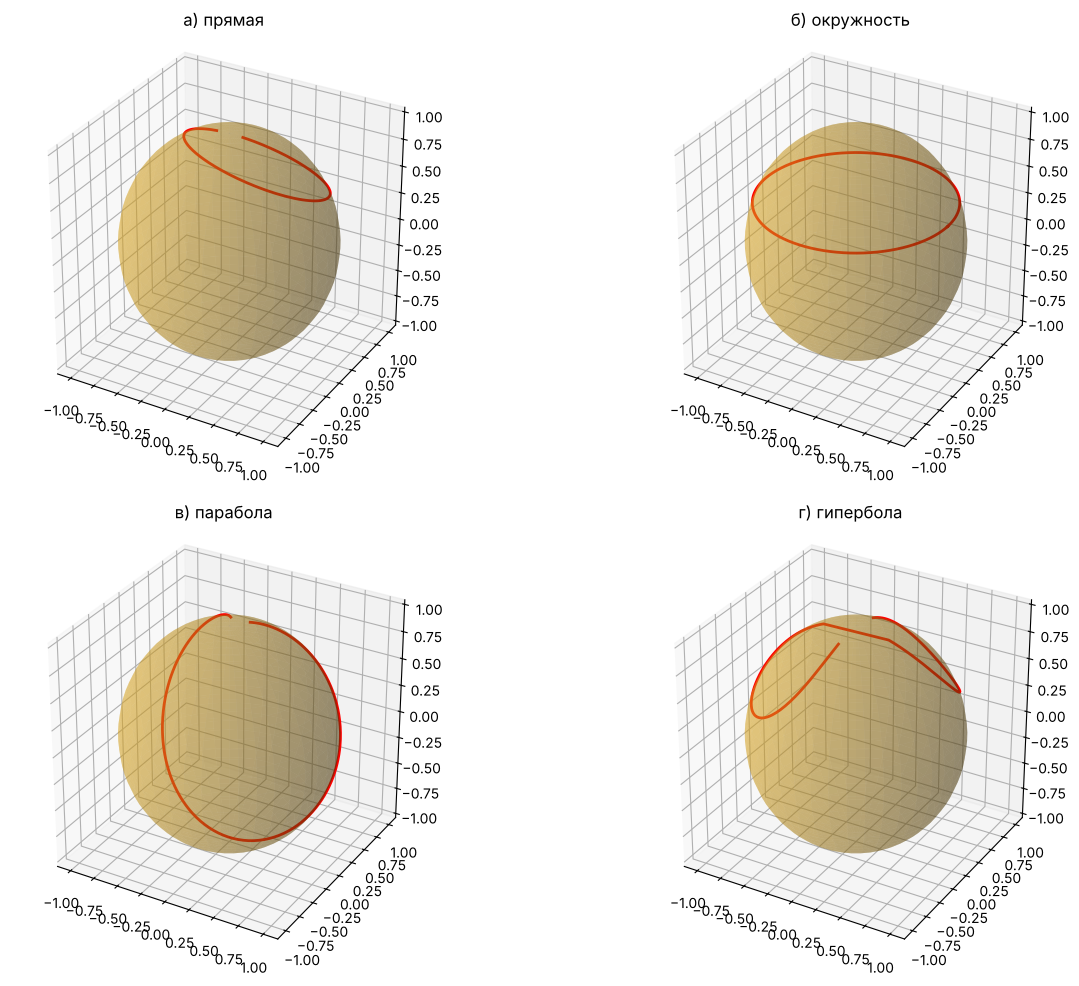

In [13]:
def stereographic(zvals):
    # переводит массив комплексных чисел z в точки (X, Y, H) на сфере Римана
    zz = np.asarray(zvals, dtype=complex)
    mod2 = np.abs(zz)**2                       # |z|^2 для каждой точки
    X = 2*zz.real / (1 + mod2)
    Y = 2*zz.imag / (1 + mod2)
    H = (mod2 - 1) / (mod2 + 1)
    return X, Y, H

def draw_sphere(ax):
    u = np.linspace(0, 2*np.pi, 40); v = np.linspace(0, np.pi, 40)
    xs = np.outer(np.cos(u), np.sin(v)); ys = np.outer(np.sin(u), np.sin(v)); zs = np.outer(np.ones_like(u), np.cos(v))
    ax.plot_surface(xs, ys, zs, color='goldenrod', alpha=0.35, linewidth=0)  # полупрозрачная сфера-подложка

fig = plt.figure(figsize=(14, 10))

# a) прямая: z(t) = t + i   (прямая, параллельная действительной оси)
t = np.linspace(-15, 15, 600)
line_z = t + 1j*1.0
ax = fig.add_subplot(2, 2, 1, projection='3d')
draw_sphere(ax)
X, Y, H = stereographic(line_z)
ax.plot(X, Y, H, color='red', linewidth=2)
ax.set_title('a) прямая'); ax.set_box_aspect([1, 1, 1])

# б) окружность: z(t) = 1.5*e^{it}
t = np.linspace(0, 2*np.pi, 400)
circ_z = 1.5*np.exp(1j*t)
ax = fig.add_subplot(2, 2, 2, projection='3d')
draw_sphere(ax)
X, Y, H = stereographic(circ_z)
ax.plot(X, Y, H, color='red', linewidth=2)
ax.set_title('б) окружность'); ax.set_box_aspect([1, 1, 1])

# в) парабола: y = x^2/2 -> z(t) = t + i*t^2/2
t = np.linspace(-4, 4, 600)
par_z = t + 1j*(t**2)/2
ax = fig.add_subplot(2, 2, 3, projection='3d')
draw_sphere(ax)
X, Y, H = stereographic(par_z)
ax.plot(X, Y, H, color='red', linewidth=2)
ax.set_title('в) парабола'); ax.set_box_aspect([1, 1, 1])

# г) гипербола: xy = 1 -> z(t) = t + i/t (берём обе ветви)
t1 = np.linspace(0.15, 6, 300); t2 = np.linspace(-6, -0.15, 300)
hyp_z = np.concatenate([t1 + 1j/t1, t2 + 1j/t2])
ax = fig.add_subplot(2, 2, 4, projection='3d')
draw_sphere(ax)
X, Y, H = stereographic(hyp_z)
ax.plot(X, Y, H, color='red', linewidth=2)
ax.set_title('г) гипербола'); ax.set_box_aspect([1, 1, 1])

plt.tight_layout()
plt.show()

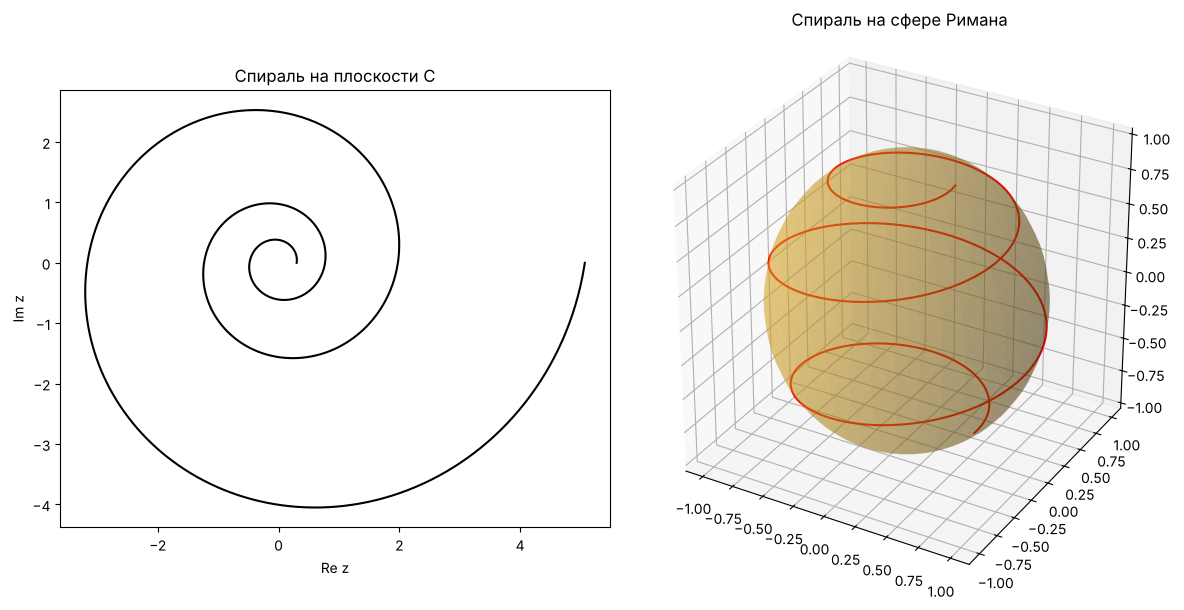

In [14]:
# Логарифмическая спираль r = a*e^(b*phi) на плоскости, затем её образ на сфере Римана
a_sp, b_sp = 0.3, 0.15                          # параметры спирали (подобраны для наглядности)
phi = np.linspace(0, 6*np.pi, 1200)             # угол меняется на несколько полных оборотов
r_sp = a_sp*np.exp(b_sp*phi)                    # радиус по формуле логарифмической спирали
spiral_z = r_sp*np.exp(1j*phi)                  # комплексные точки спирали z = r*e^{i*phi}

fig = plt.figure(figsize=(12, 6))

ax1 = fig.add_subplot(1, 2, 1)                  # спираль на обычной комплексной плоскости
ax1.plot(spiral_z.real, spiral_z.imag, color='black')
ax1.set_aspect('equal'); ax1.set_title('Спираль на плоскости C')
ax1.set_xlabel('Re z'); ax1.set_ylabel('Im z')

ax2 = fig.add_subplot(1, 2, 2, projection='3d') # образ спирали на сфере Римана
draw_sphere(ax2)
X, Y, H = stereographic(spiral_z)
ax2.plot(X, Y, H, color='red', linewidth=1.5)
ax2.set_title('Спираль на сфере Римана'); ax2.set_box_aspect([1, 1, 1])

plt.tight_layout()
plt.show()

**Ответ:** стереографическая проекция прямой и гиперболы даёт кривые, проходящие через северный полюс сферы (точку $z=\infty$), а проекция окружности и параболы (которая при добавлении бесконечно удалённой точки тоже проходит через полюс) образует замкнутые/проходящие через полюс кривые на сфере — что согласуется с рисунками в условии. Логарифмическая спираль, бесконечно наматываясь при $\varphi\to-\infty$ на точку $z=0$ и уходя на бесконечность при $\varphi\to+\infty$, на сфере Римана превращается в кривую, стягивающуюся к южному полюсу ($z=0$) и наматывающуюся на северный полюс ($z=\infty$) — именно это показано на Рис. 5 условия.